# 01 — Terrain and clear-sky insolation

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

This notebook builds the physical base layer: a 30 m terrain grid over the study
rectangle, the ray-marched sky horizon around it, and clear-sky plane-of-array
insolation for the periods that matter to a winter resort.

**What this is.** An independent study on open data and own code. It is not
commissioned by, affiliated with, or endorsed by any resort operator, and it uses
no commercial or NDA material. The official November 2026 statement on the Almaty
SuperSki cluster names no individual resort site, so the rectangle analysed here
is the author's own choice of study area, not a project boundary.

**What it is not.** The study rectangle is not a resort boundary and not a trail
plan. Resort limits and designed pistes require official GIS layers.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config import (AOI_BBOX_WGS84, OUT_PNG, DEM_RES_M, FOCUS_BAND, GROUND_ALBEDO,
                    HORIZON_BUFFER_M, HORIZON_N_AZIMUTH, INSOLATION_PERIODS,
                    OUT_TAB, OUT_TIF, PLATEAU_POINT, SKIABLE_SLOPE_MAX,
                    SKIABLE_SLOPE_MIN)
from dem import write_geotiff
from grids import DEM_GRID, wgs84_rect_area_km2
from pipeline_terrain import all_insolation, terrain
from viz import ELEV_CMAP, map_panel, save

pd.set_option("display.width", 130)
print(f"study rectangle (W,S,E,N) = {AOI_BBOX_WGS84}")
print(f"analysis grid  : {DEM_GRID.shape[0]} x {DEM_GRID.shape[1]} cells @ {DEM_RES_M:.0f} m, "
      f"{DEM_GRID.crs}")
print(f"grid area      : {DEM_GRID.area_km2:.2f} km2")
print(f"WGS84 rectangle: {wgs84_rect_area_km2():.2f} km2 (geodesic, on the ellipsoid)")

study rectangle (W,S,E,N) = (76.96, 43.105, 77.065, 43.174)
analysis grid  : 263 x 292 cells @ 30 m, EPSG:32643
grid area      : 69.12 km2
WGS84 rectangle: 65.48 km2 (geodesic, on the ellipsoid)


The grid is the axis-aligned UTM bounding box of the WGS84 rectangle, snapped
outward to whole 30 m cells. Meridian convergence at 77°E is about 1.4°, so the
projected rectangle is slightly rotated and its bounding box is larger than the
rectangle itself — that is the whole of the 69.12 vs 65.48 km² difference.

### QA: the plateau reference point must fall inside the rectangle

In [2]:
from pyproj import Transformer

tr = Transformer.from_crs("EPSG:4326", DEM_GRID.crs, always_xy=True)
px, py = tr.transform(*PLATEAU_POINT)
inside = (DEM_GRID.xmin < px < DEM_GRID.xmax) and (DEM_GRID.ymin < py < DEM_GRID.ymax)
print(f"plateau {PLATEAU_POINT} -> UTM ({px:.0f}, {py:.0f}); inside grid: {inside}")
assert inside, "plateau reference point is outside the study rectangle"

plateau (77.00433, 43.14239) -> UTM (662994, 4778577); inside grid: True


## 1. Terrain

Copernicus DEM GLO-30 tiles `N43_E076` and `N43_E077` (AWS Open Data, public,
EGM2008 vertical datum), merged and reprojected to EPSG:32643 at 30 m.
Slope and aspect use the Horn (1981) 3×3 operator; aspect is clockwise from
**true** north (grid north in UTM 43N differs by the ~1.4° convergence, which is
removed by computing aspect after projection and is below the DEM's own
directional accuracy).

In [3]:
t = terrain()          # cached; recompute with terrain(force=True)
dem, slope, aspect, svf = t["dem"], t["slope"], t["aspect"], t["svf"]
azimuths, horizon = t["azimuths"], t["horizon"]

print(f"elevation : {np.nanmin(dem):.0f} – {np.nanmax(dem):.0f} m "
      f"(median {np.nanmedian(dem):.0f} m)")
print(f"slope     : median {np.nanmedian(slope):.1f}°, "
      f"p90 {np.nanpercentile(slope,90):.1f}°, max {np.nanmax(slope):.1f}°")
print(f"sky view  : {np.nanmin(svf):.3f} – {np.nanmax(svf):.3f} "
      f"(median {np.nanmedian(svf):.3f})")
print(f"horizon   : {HORIZON_N_AZIMUTH} azimuths, {HORIZON_BUFFER_M/1000:.0f} km search radius, "
      f"median {np.nanmedian(horizon):.1f}°")

elevation : 1271 – 3318 m (median 2077 m)
slope     : median 28.8°, p90 37.0°, max 53.0°
sky view  : 0.652 – 0.998 (median 0.889)
horizon   : 36 azimuths, 6 km search radius, median 14.5°


### QA: slope, aspect and sky view factor against closed-form cases

In [4]:
from dem import horizon_angles, sky_view_factor, slope_aspect
from grids import Grid

rows = []
yy, xx = np.mgrid[0:40, 0:40].astype(float)
X, Y = xx * 30.0, -yy * 30.0
for true_asp in (0, 45, 90, 135, 180, 225, 270, 315):
    a = np.radians(true_asp)
    z = 2000.0 - np.tan(np.radians(20.0)) * (X * np.sin(a) + Y * np.cos(a))
    s_, a_ = slope_aspect(z, 30.0)
    rows.append({"test": "synthetic plane", "expected": f"slope 20°, aspect {true_asp}°",
                 "computed": f"slope {s_[20,20]:.2f}°, aspect {a_[20,20]:.2f}°"})

az_t = np.arange(72) * 5.0
for beta in (0, 20, 40):
    got = float(sky_view_factor(az_t, np.zeros((72, 1, 1), "float32"),
                                np.array([[float(beta)]]), np.array([[180.0]]))[0, 0])
    rows.append({"test": "sky view factor, unobstructed plane",
                 "expected": f"(1+cos {beta}°)/2 = {(1+np.cos(np.radians(beta)))/2:.4f}",
                 "computed": f"{got:.4f}"})
got = float(sky_view_factor(az_t, np.full((72, 1, 1), 30.0, "float32"),
                            np.array([[0.0]]), np.array([[0.0]]))[0, 0])
rows.append({"test": "sky view factor, flat pixel in a 30° skyline",
             "expected": f"cos²30° = {np.cos(np.radians(30))**2:.4f}", "computed": f"{got:.4f}"})

qa = pd.DataFrame(rows)
qa.to_csv(OUT_TAB / "qa_terrain_validation.csv", index=False)
print(qa.to_string(index=False))

                                        test               expected                     computed
                             synthetic plane   slope 20°, aspect 0°   slope 20.00°, aspect 0.00°
                             synthetic plane  slope 20°, aspect 45°  slope 20.00°, aspect 45.00°
                             synthetic plane  slope 20°, aspect 90°  slope 20.00°, aspect 90.00°
                             synthetic plane slope 20°, aspect 135° slope 20.00°, aspect 135.00°
                             synthetic plane slope 20°, aspect 180° slope 20.00°, aspect 180.00°
                             synthetic plane slope 20°, aspect 225° slope 20.00°, aspect 225.00°
                             synthetic plane slope 20°, aspect 270° slope 20.00°, aspect 270.00°
                             synthetic plane slope 20°, aspect 315° slope 20.00°, aspect 315.00°
         sky view factor, unobstructed plane  (1+cos 0°)/2 = 1.0000                       1.0000
         sky view factor, unob

## 2. Terrain maps

bare relief for the brief: 01_terrain_3d_bare.png 1256x693


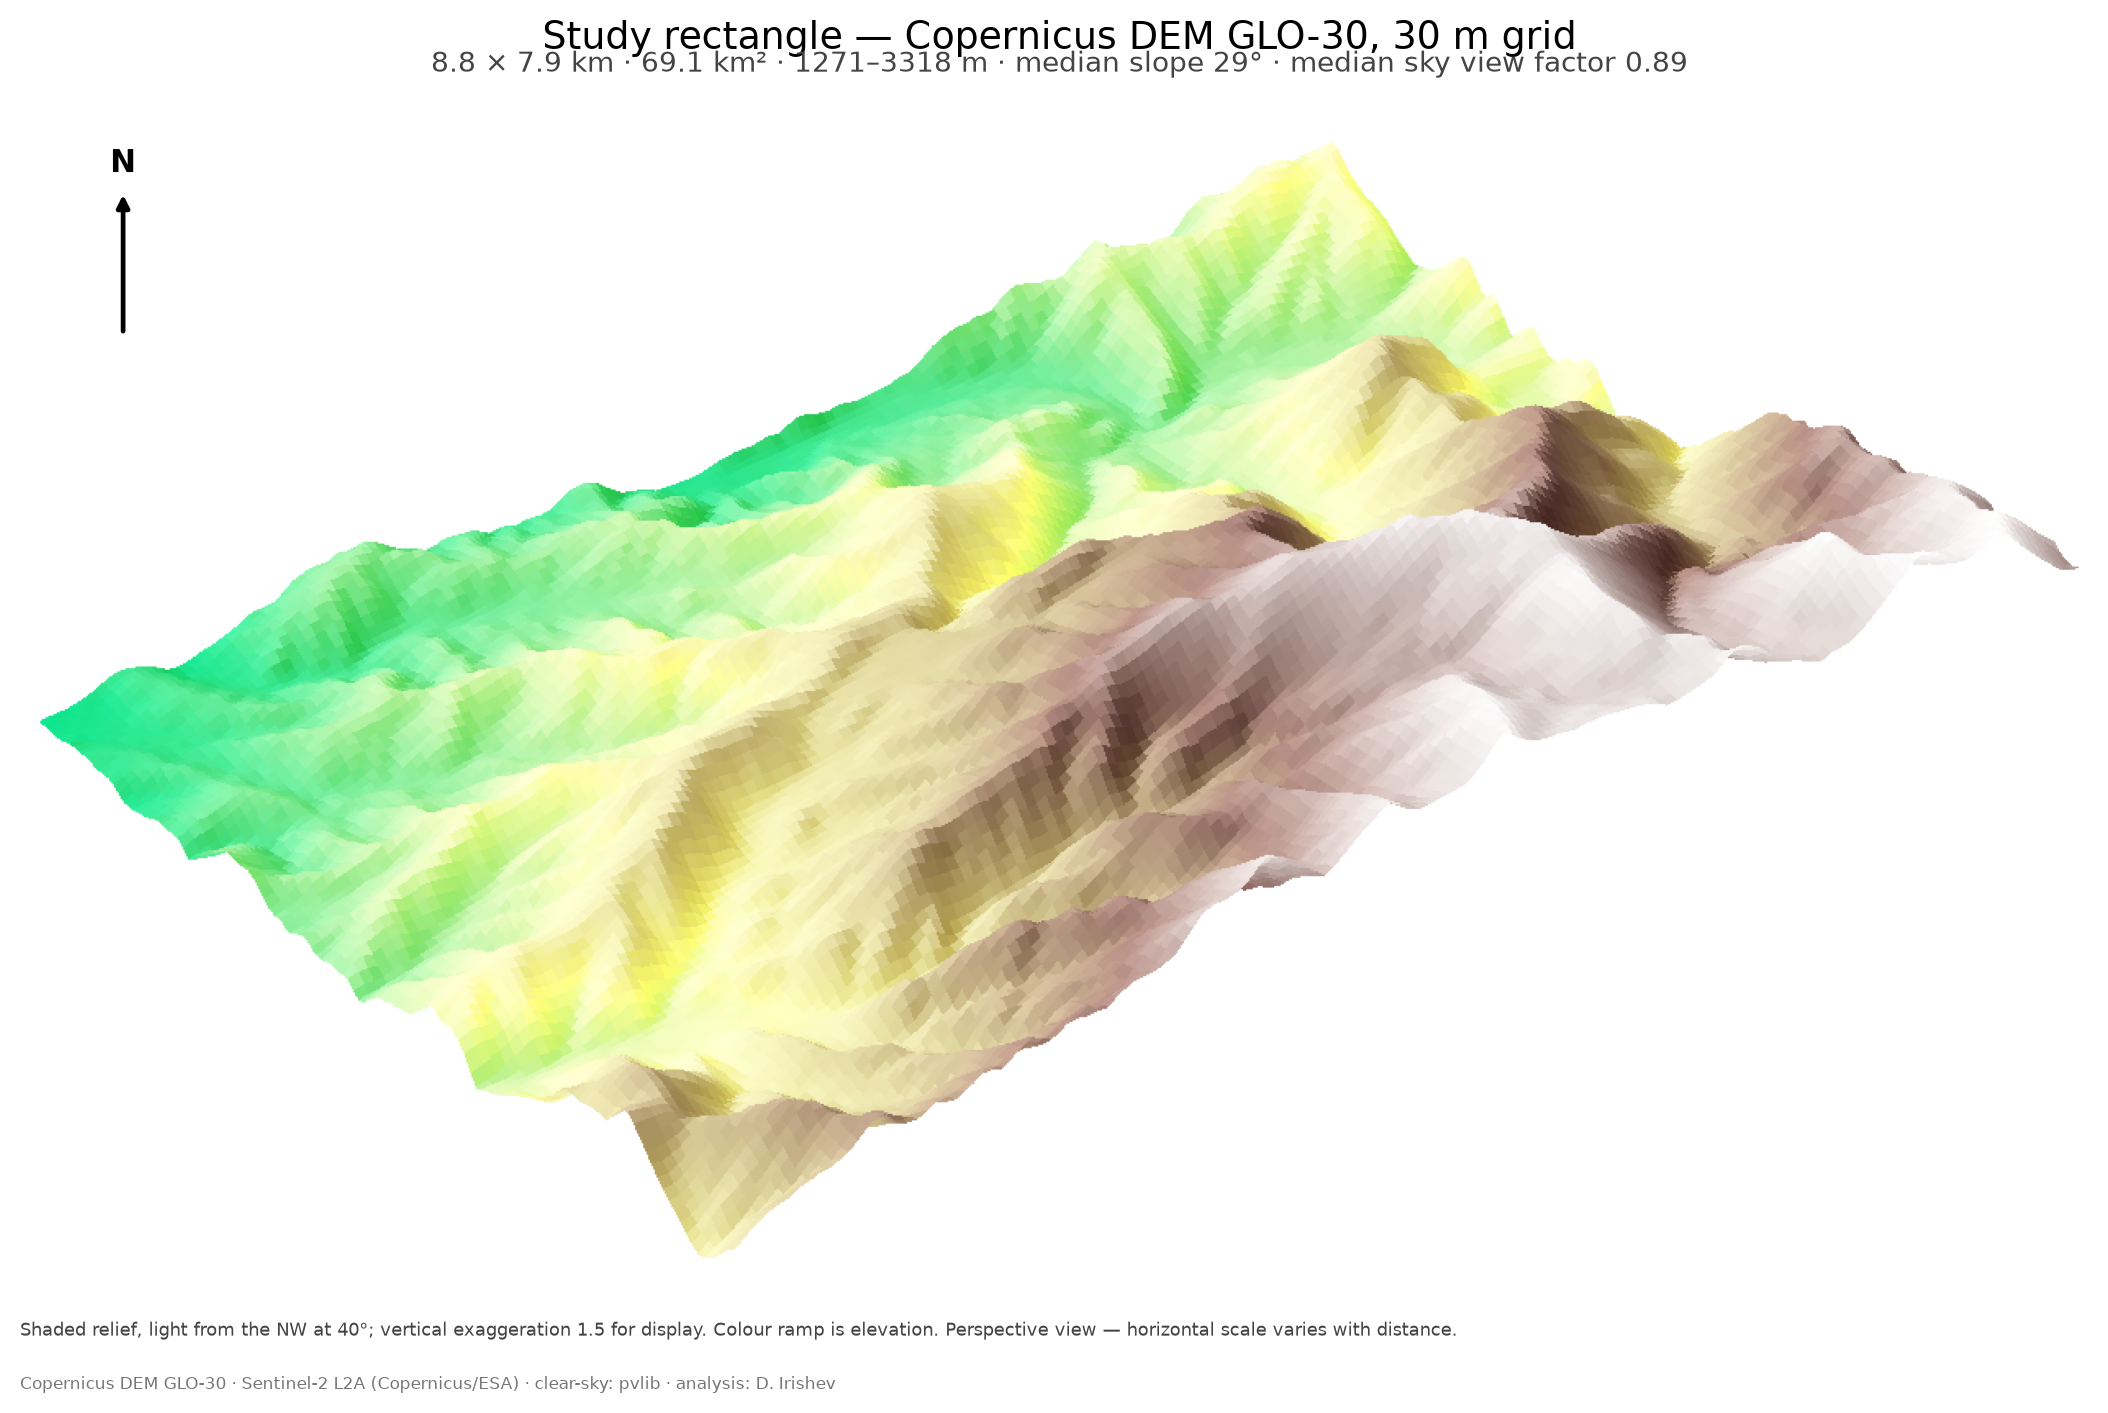

saved 01_terrain_3d.png


In [5]:
from viz import render_3d_relief

relief = render_3d_relief(dem, DEM_GRID)
h, w = relief.shape[:2]
fig, ax = plt.subplots(figsize=(10.5, 10.5 * h / w + 1.0))
ax.imshow(relief)
ax.set_axis_off()

# North arrow only: this is a perspective view, so a single scale bar would be wrong.
ax.annotate("", xy=(0.045, 0.95), xytext=(0.045, 0.82), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color="black", lw=1.7))
ax.text(0.045, 0.965, "N", transform=ax.transAxes, ha="center", fontsize=11,
        fontweight="bold")

km_w = (DEM_GRID.xmax - DEM_GRID.xmin) / 1000
km_h = (DEM_GRID.ymax - DEM_GRID.ymin) / 1000
ax.set_title("Study rectangle \u2014 Copernicus DEM GLO-30, 30 m grid",
             fontsize=13.5, pad=30)
fig.text(0.5, 0.905,
         f"{km_w:.1f} \u00d7 {km_h:.1f} km \u00b7 {DEM_GRID.area_km2:.1f} km\u00b2 \u00b7 "
         f"1271\u20133318 m \u00b7 median slope {np.nanmedian(slope):.0f}\u00b0 \u00b7 "
         f"median sky view factor {np.nanmedian(svf):.2f}",
         ha="center", fontsize=10, color="#444")
fig.subplots_adjust(left=0.01, right=0.99, top=0.875, bottom=0.01)
from PIL import Image as _PILImage
_PILImage.fromarray(relief).save(OUT_PNG / "01_terrain_3d_bare.png")
print(f"bare relief for the brief: 01_terrain_3d_bare.png {relief.shape[1]}x{relief.shape[0]}")

save(fig, "01_terrain_3d.png",
     "Shaded relief, light from the NW at 40\u00b0; vertical exaggeration 1.5 for display. "
     "Colour ramp is elevation. Perspective view \u2014 horizontal scale varies with distance.")
print("saved 01_terrain_3d.png")

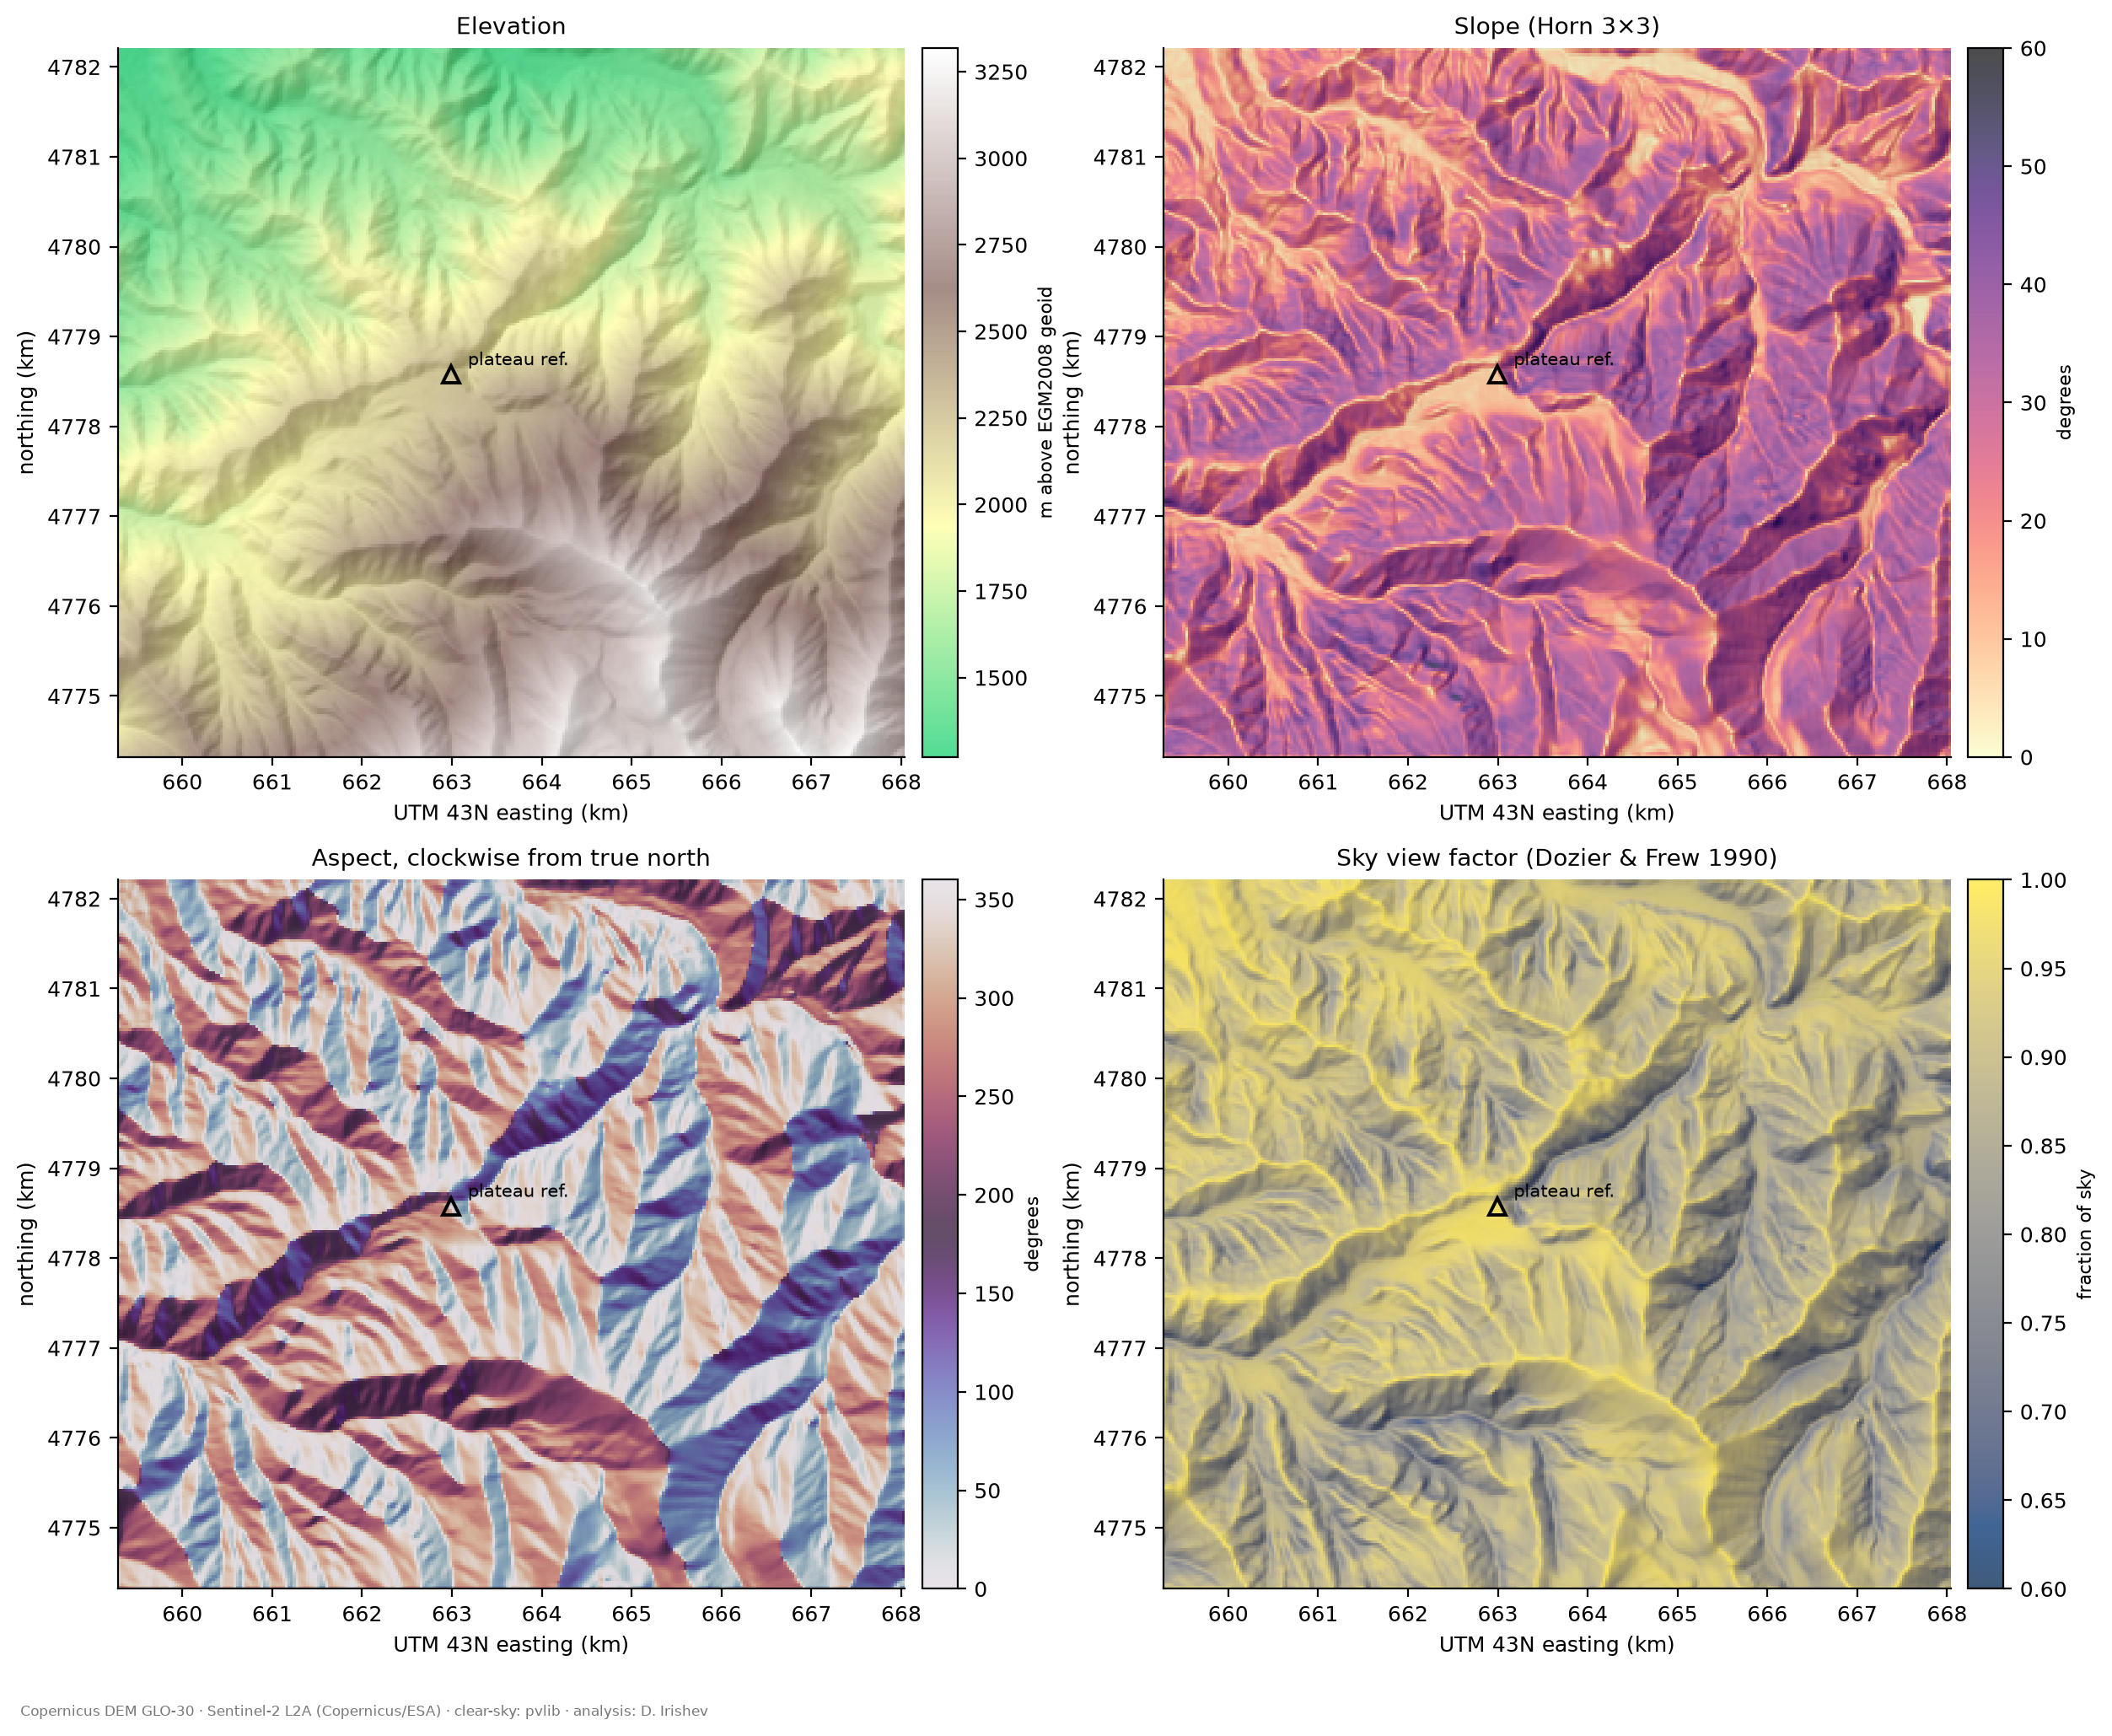

saved 01_terrain_panels.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 10))
map_panel(axes[0, 0], dem, DEM_GRID, ELEV_CMAP, title="Elevation",
          cbar_label="m above EGM2008 geoid", dem=dem, shade=0.3)
map_panel(axes[0, 1], slope, DEM_GRID, "magma_r", 0, 60, title="Slope (Horn 3×3)",
          cbar_label="degrees", dem=dem, shade=0.3)
map_panel(axes[1, 0], aspect, DEM_GRID, "twilight", 0, 360,
          title="Aspect, clockwise from true north", cbar_label="degrees",
          dem=dem, shade=0.25)
map_panel(axes[1, 1], svf, DEM_GRID, "cividis", 0.6, 1.0,
          title="Sky view factor (Dozier & Frew 1990)", cbar_label="fraction of sky",
          dem=dem, shade=0.25)
fig.tight_layout()
save(fig, "01_terrain_panels.png")
print("saved 01_terrain_panels.png")

## 3. Clear-sky insolation

`pvlib` Ineichen–Perez clear sky with monthly Linke turbidity climatology,
evaluated on 30-minute steps. Clear sky is computed at seven altitude levels
spanning the grid and interpolated per pixel, so the ~2 km of relief inside the
rectangle is not collapsed to one atmosphere.

* **direct** — DNI × cos(incidence), set to zero where the sun is below the
  ray-marched horizon or behind the slope;
* **diffuse** — isotropic, DHI × sky view factor;
* **reflected** — GHI × albedo × (1 − SVF), with albedo fixed at
  **0.50** for the snow season.

The reflected term is the weakest assumption here: a single seasonal albedo
stands in for a surface that ranges from fresh snow (~0.8) to bare rock and
conifer (~0.1). It contributes under 10% of the seasonal total, and the
low-vs-high exposure contrast in notebook 03 is reproduced on direct beam alone.

In [7]:
ins = all_insolation(t)
rows = []
for label in INSOLATION_PERIODS:
    r = ins[label]
    rows.append({
        "period": label, "start": r["meta"]["start"], "end": r["meta"]["end"],
        "median_total_kwh_m2": round(float(np.nanmedian(r["total"])), 1),
        "p05_total": round(float(np.nanpercentile(r["total"], 5)), 1),
        "p95_total": round(float(np.nanpercentile(r["total"], 95)), 1),
        "median_direct": round(float(np.nanmedian(r["direct"])), 1),
        "median_diffuse": round(float(np.nanmedian(r["diffuse"])), 1),
        "median_reflected": round(float(np.nanmedian(r["reflected"])), 1),
        "median_shaded_fraction_of_daylight": round(float(np.nanmedian(r["shaded_fraction"])), 3),
    })
insol_summary = pd.DataFrame(rows)
insol_summary.to_csv(OUT_TAB / "insolation_period_summary.csv", index=False)
print(insol_summary.to_string(index=False))

 period      start        end  median_total_kwh_m2  p05_total  p95_total  median_direct  median_diffuse  median_reflected  median_shaded_fraction_of_daylight
    dec 2022-12-01 2022-12-31                 21.6        6.5      126.6           14.4             3.2               4.2                               0.704
    mar 2023-03-01 2023-03-31                143.0       63.7      245.3          125.1             8.3              10.4                               0.276
nov_dec 2022-11-01 2022-12-31                 67.0       16.7      277.7           50.4             7.3               9.5                               0.624
jan_feb 2023-01-01 2023-02-28                106.0       24.1      316.9           86.9             8.4              11.4                               0.520
mar_apr 2023-03-01 2023-04-30                346.8      200.3      519.3          305.2            20.1              23.7                               0.242


### December and March on a shared scale

A shared colour scale is the point of this figure: the December range is a small
slice of the March range, and plotting each on its own scale would hide that.

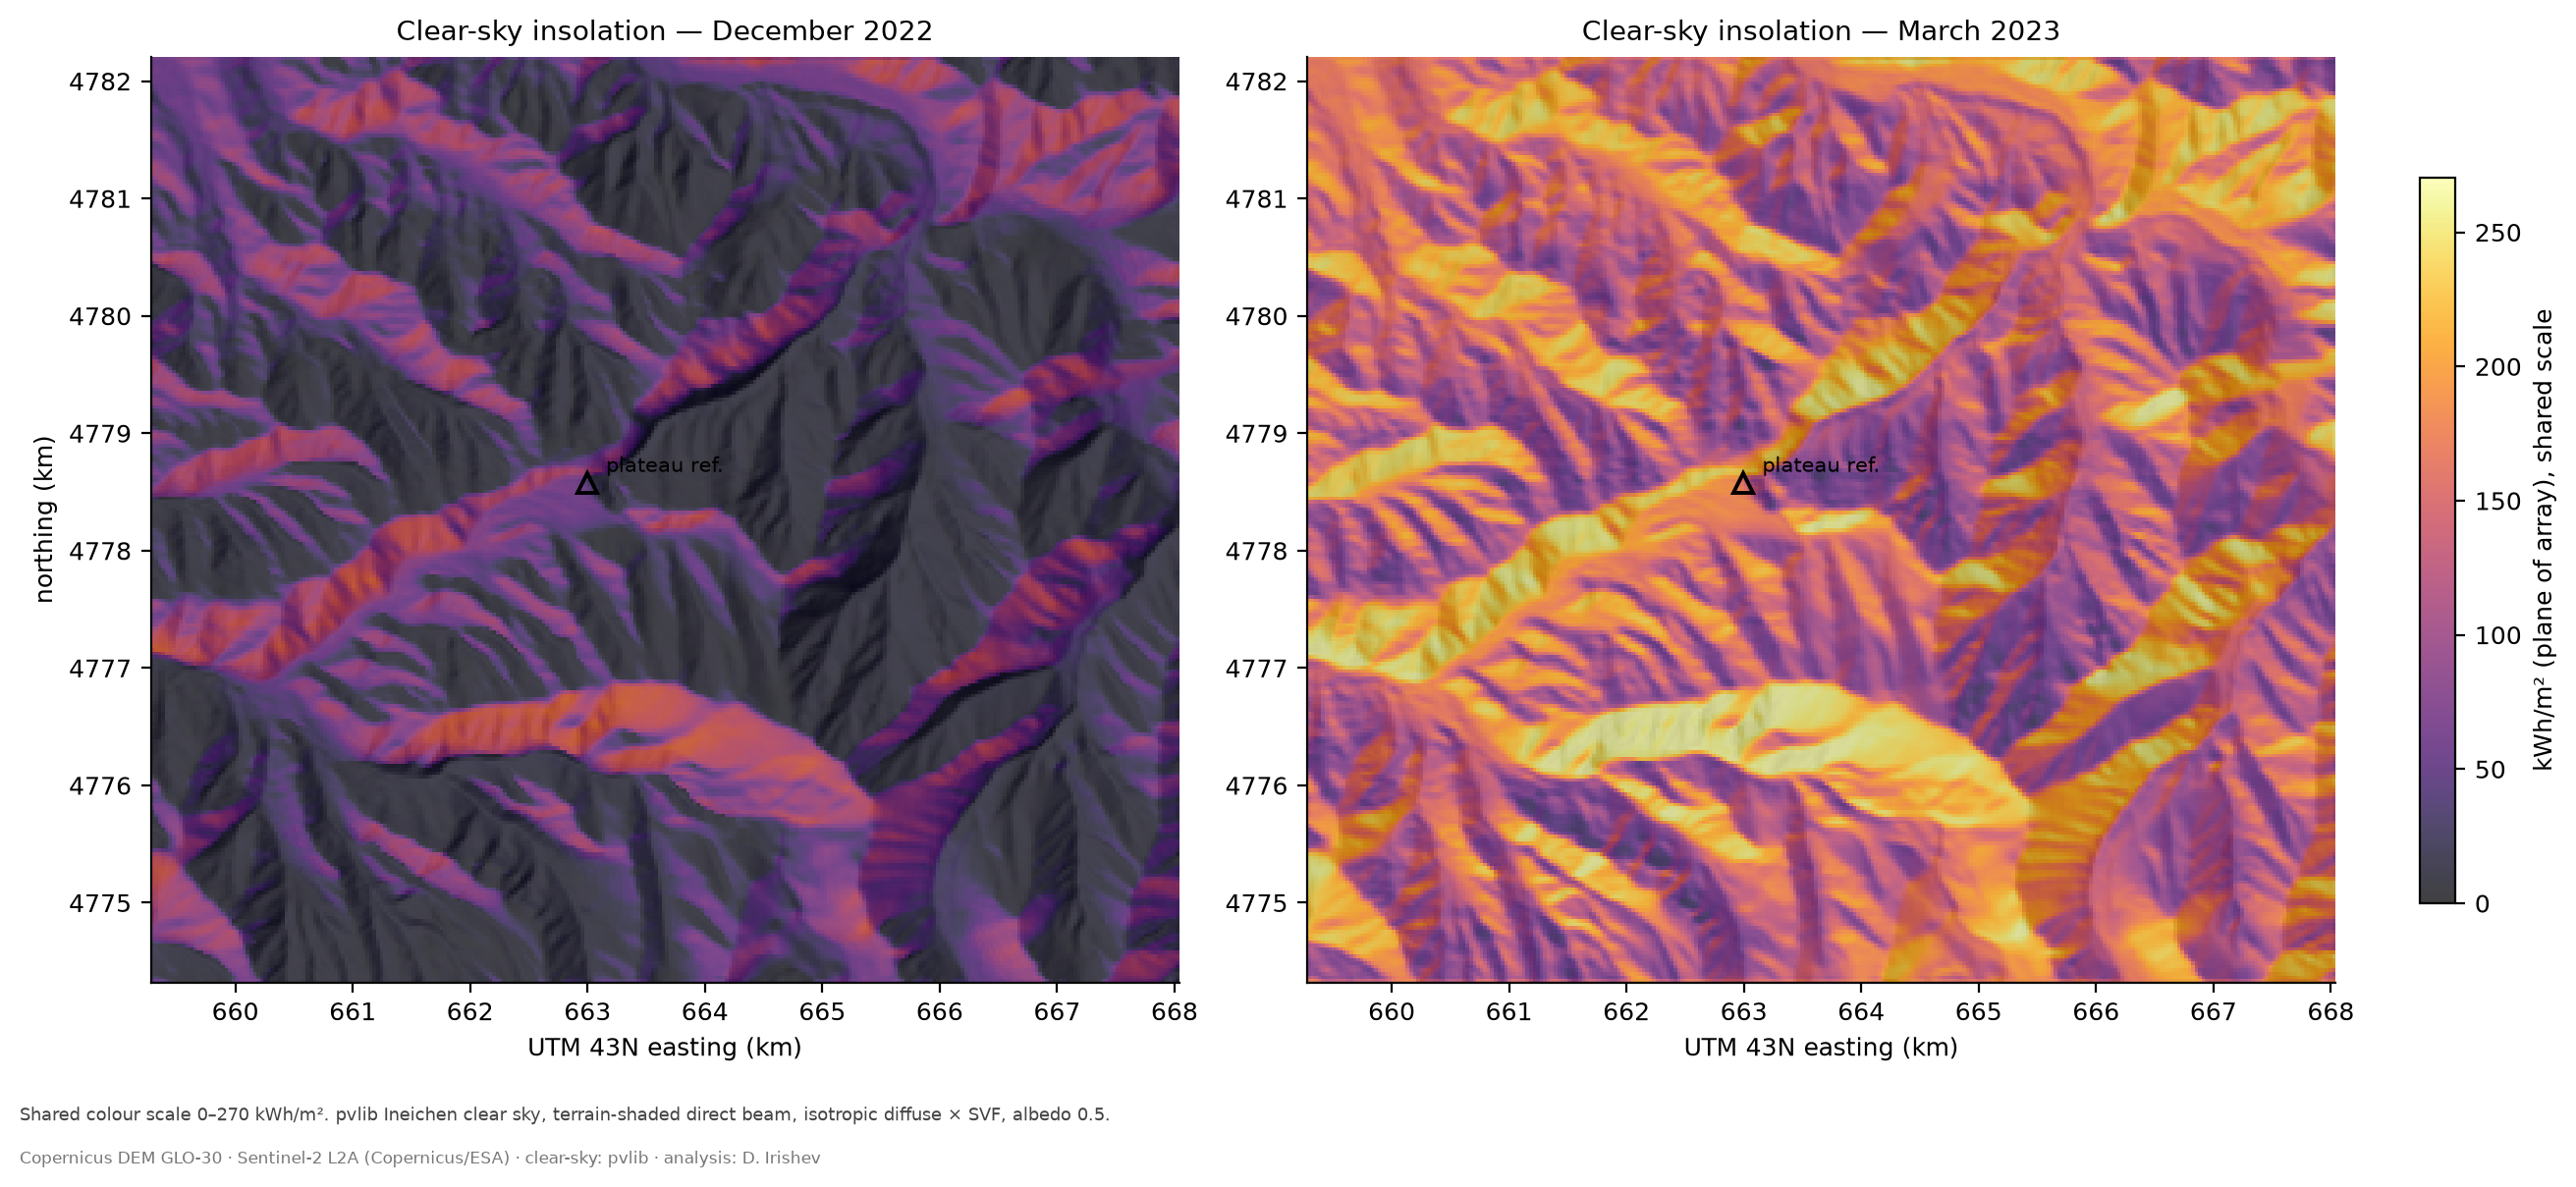

saved, shared scale 0–270 kWh/m²


In [8]:
vmax = float(np.nanpercentile(ins["mar"]["total"], 99.5))
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.6))
for ax, lab, title in ((axes[0], "dec", "December 2022"), (axes[1], "mar", "March 2023")):
    im = map_panel(ax, ins[lab]["total"], DEM_GRID, "inferno", 0, vmax,
                   title=f"Clear-sky insolation — {title}",
                   dem=dem, shade=0.25, cbar=False)
axes[1].set_ylabel("")
fig.tight_layout(rect=(0, 0, 0.93, 1))
cax = fig.add_axes([0.945, 0.17, 0.014, 0.66])
cb = fig.colorbar(im, cax=cax)
cb.set_label("kWh/m² (plane of array), shared scale", fontsize=9)
save(fig, "01_insolation_dec_mar_shared_scale.png",
     f"Shared colour scale 0–{vmax:.0f} kWh/m². pvlib Ineichen clear sky, terrain-shaded "
     f"direct beam, isotropic diffuse × SVF, albedo {GROUND_ALBEDO}.")
print(f"saved, shared scale 0–{vmax:.0f} kWh/m²")

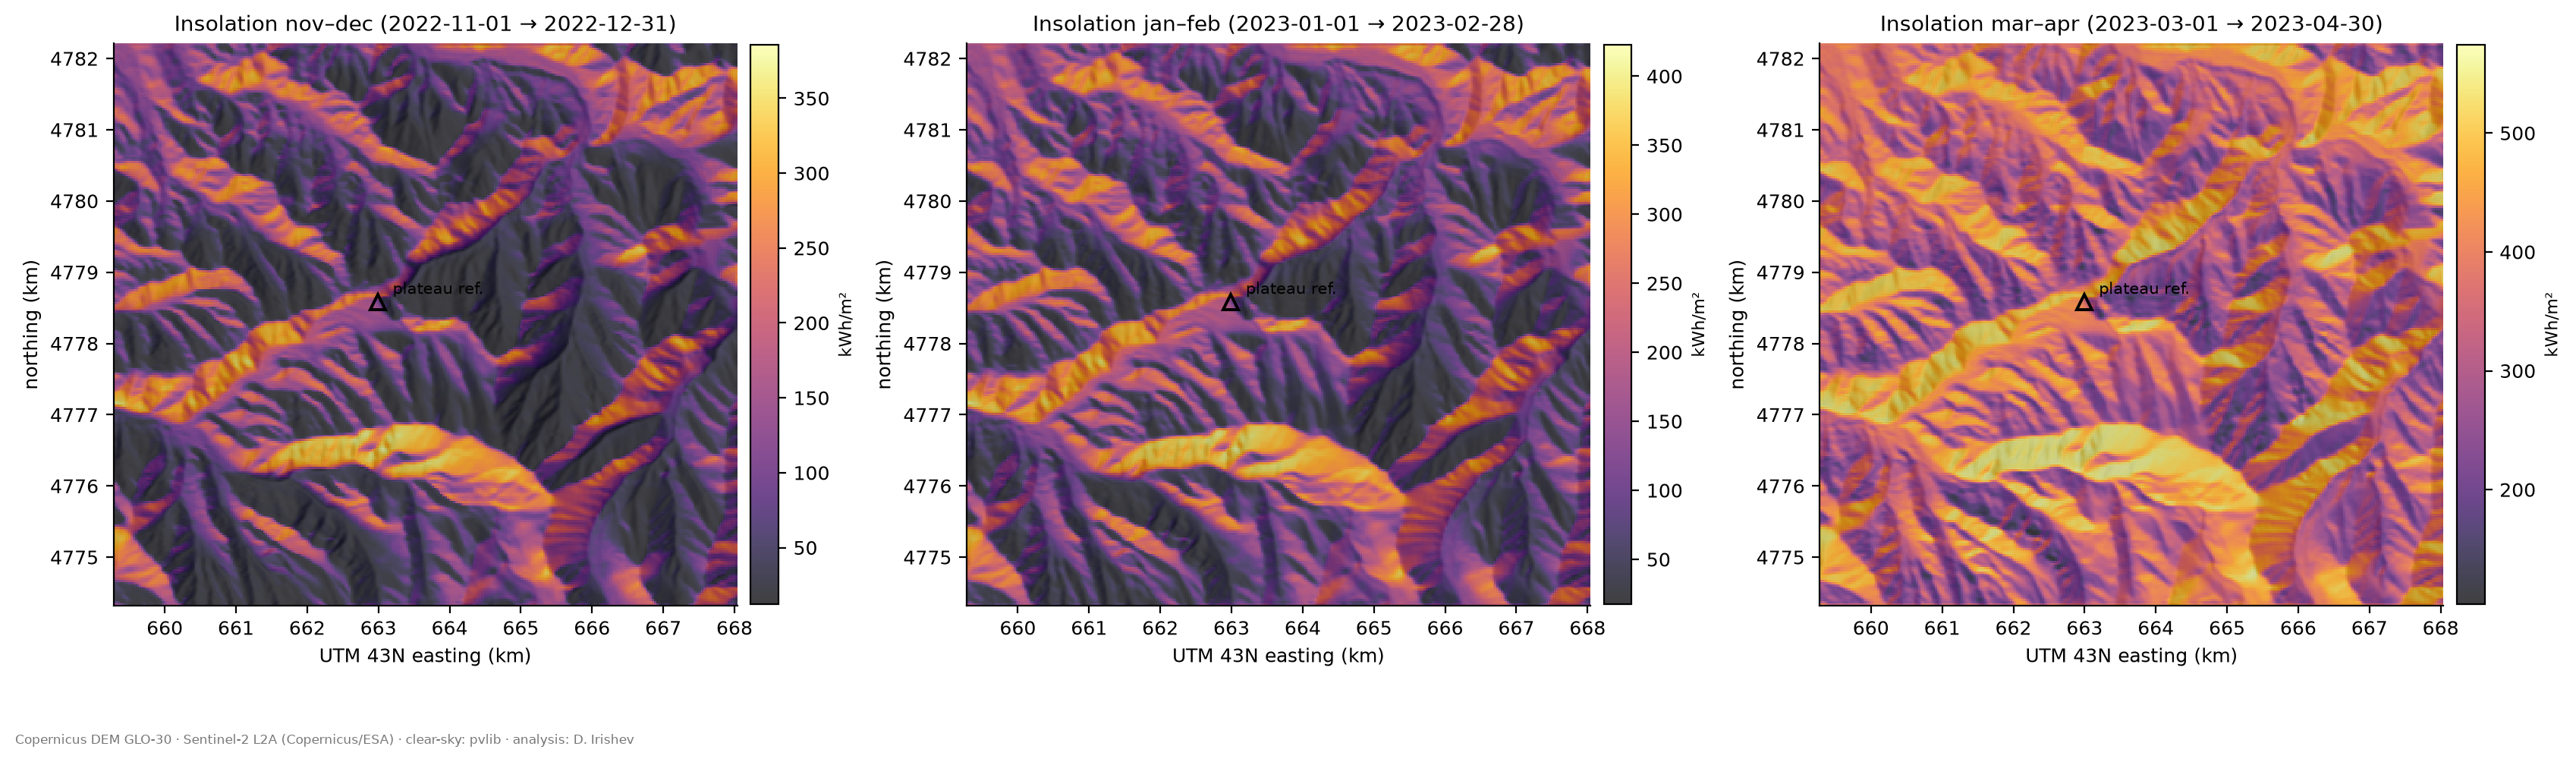

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailau-ski-terrain-analytics/outputs/png/01_insolation_seasonal_windows.png')

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, lab in zip(axes, ("nov_dec", "jan_feb", "mar_apr")):
    map_panel(ax, ins[lab]["total"], DEM_GRID, "inferno",
              title=f"Insolation {lab.replace('_','–')} "
                    f"({ins[lab]['meta']['start']} → {ins[lab]['meta']['end']})",
              cbar_label="kWh/m²", dem=dem, shade=0.25)
fig.tight_layout()
save(fig, "01_insolation_seasonal_windows.png")

## 4. Insolation by elevation band and aspect

In [10]:
from planning import aspect_class, elevation_bands, skiable_mask

acl = aspect_class(aspect)
bands = elevation_bands(dem)
ski = skiable_mask(slope)
rows = []
for b in np.unique(bands[np.isfinite(bands) & ski]):
    for code, nm in ((0, "north"), (1, "south"), (2, "east/west")):
        m = ski & (bands == b) & (acl == code)
        if m.sum() < 25:
            continue
        rec = {"elev_band_m": float(b), "band_label": f"{int(b)}–{int(b)+100}",
               "aspect_sector": nm, "n_pixels": int(m.sum()),
               "area_km2": round(int(m.sum()) * DEM_RES_M**2 / 1e6, 4)}
        for lab in INSOLATION_PERIODS:
            rec[f"median_{lab}_kwh_m2"] = round(float(np.nanmedian(ins[lab]["total"][m])), 1)
        rows.append(rec)
band_aspect = pd.DataFrame(rows)
band_aspect.to_csv(OUT_TAB / "insolation_by_band_and_aspect.csv", index=False)
print(f"{len(band_aspect)} band × aspect groups "
      f"(15–35° slopes only, ≥25 cells per group)")
focus = band_aspect[band_aspect.elev_band_m == FOCUS_BAND[0]]
print(f"\n{int(FOCUS_BAND[0])}–{int(FOCUS_BAND[1])} m band:")
print(focus[["aspect_sector", "n_pixels", "median_dec_kwh_m2",
             "median_mar_kwh_m2", "median_mar_apr_kwh_m2"]].to_string(index=False))

59 band × aspect groups (15–35° slopes only, ≥25 cells per group)

2200–2300 m band:
aspect_sector  n_pixels  median_dec_kwh_m2  median_mar_kwh_m2  median_mar_apr_kwh_m2
        north      1227                8.0               94.9                  258.9
        south       301              126.8              250.7                  530.0
    east/west      1402               40.1              171.8                  400.8


## 5. GeoTIFF outputs

In [11]:
written = []
written.append(write_geotiff(OUT_TIF / "elevation_m.tif", dem, DEM_GRID, nodata=-9999,
                             description="Copernicus DEM GLO-30, EGM2008",
                             source="Copernicus DEM GLO-30 (AWS Open Data)"))
written.append(write_geotiff(OUT_TIF / "slope_deg.tif", slope, DEM_GRID, nodata=-9999,
                             description="slope, Horn 3x3, degrees"))
written.append(write_geotiff(OUT_TIF / "aspect_deg.tif", aspect, DEM_GRID, nodata=-9999,
                             description="aspect, degrees CW from true north"))
written.append(write_geotiff(OUT_TIF / "sky_view_factor.tif", svf, DEM_GRID, nodata=-9999,
                             description="sky view factor, Dozier & Frew 1990"))
written.append(write_geotiff(OUT_TIF / "horizon_mean_deg.tif",
                             np.nanmean(horizon, axis=0), DEM_GRID, nodata=-9999,
                             description=f"mean horizon elevation over {HORIZON_N_AZIMUTH} azimuths"))
for lab in INSOLATION_PERIODS:
    written.append(write_geotiff(
        OUT_TIF / f"insolation_{lab}_kwh_m2.tif", ins[lab]["total"], DEM_GRID,
        nodata=-9999, description=f"clear-sky POA insolation {lab}, kWh/m2",
        period=f"{ins[lab]['meta']['start']}..{ins[lab]['meta']['end']}",
        model=ins[lab]["meta"]["model"], albedo=str(GROUND_ALBEDO)))
    written.append(write_geotiff(
        OUT_TIF / f"insolation_{lab}_direct_kwh_m2.tif", ins[lab]["direct"], DEM_GRID,
        nodata=-9999, description=f"direct-beam component {lab}, kWh/m2"))

meta = {"grid": {"crs": DEM_GRID.crs, "res_m": DEM_GRID.res,
                 "shape": list(DEM_GRID.shape), "bounds": list(DEM_GRID.bounds),
                 "area_km2": round(DEM_GRID.area_km2, 3)},
        "aoi_bbox_wgs84": list(AOI_BBOX_WGS84),
        "wgs84_rect_area_km2": round(wgs84_rect_area_km2(), 3),
        "dem": json.loads(str(t["meta"][0])),
        "insolation": {k: ins[k]["meta"] for k in INSOLATION_PERIODS},
        "horizon": {"n_azimuth": HORIZON_N_AZIMUTH, "buffer_m": HORIZON_BUFFER_M},
        "slope_window_deg": [SKIABLE_SLOPE_MIN, SKIABLE_SLOPE_MAX]}
json.dump(meta, open(OUT_TIF / "terrain_metadata.json", "w"), indent=1)
print(f"{len(written)} GeoTIFFs written to outputs/geotiff/")
for p in written:
    print(f"  {p.name}")

15 GeoTIFFs written to outputs/geotiff/
  elevation_m.tif
  slope_deg.tif
  aspect_deg.tif
  sky_view_factor.tif
  horizon_mean_deg.tif
  insolation_dec_kwh_m2.tif
  insolation_dec_direct_kwh_m2.tif
  insolation_mar_kwh_m2.tif
  insolation_mar_direct_kwh_m2.tif
  insolation_nov_dec_kwh_m2.tif
  insolation_nov_dec_direct_kwh_m2.tif
  insolation_jan_feb_kwh_m2.tif
  insolation_jan_feb_direct_kwh_m2.tif
  insolation_mar_apr_kwh_m2.tif
  insolation_mar_apr_direct_kwh_m2.tif
